# Модель длительности поездки

**Задача.** Предсказать длительность поездки в минутах по признакам, известным в момент посадки: расстояние, час, день недели, районы посадки и высадки. Простые модели по нарастающей, оценка на отложенном по времени периоде, и связка с первым ноутбуком: как изменились остатки модели в зоне платы и вне её.

**Данные.** `mart.ml_trips`: воспроизводимая случайная выборка около 300 тыс. поездок внутри Манхэттена, целевая переменная `duration_min`.

**План.**
1. Данные, признаки, деление по времени.
2. Бейзлайн и линейная регрессия.
3. kNN: подбор k на подвыборке.
4. Связка с первым ноутбуком: остатки модели в `cbd` и `control` до и после платы.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import KFold, cross_val_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sys.path.append(str(Path.cwd().parent / "src"))
from db import get_engine

SEED = 42

TRAIN_START, TRAIN_END = pd.Timestamp("2024-10-01"), pd.Timestamp("2024-11-30")
TEST_START, TEST_END = pd.Timestamp("2024-12-01"), pd.Timestamp("2024-12-19")

NUMERIC = ["trip_distance"]
CATEGORICAL = ["pickup_hour", "weekday", "pulocationid", "dolocationid"]
TARGET = "duration_min"

KNN_K = [5, 10, 20, 40, 80, 160, 320]
KNN_SAMPLE = 20_000

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

## 1. Данные и признаки

`trip_distance` — число, остальные четыре признака — категории. Час и день недели тоже категории: зависимость длительности от часа не монотонная (пробки утром и вечером), а one-hot даёт по коэффициенту на каждый час.

Категории кодируются `OneHotEncoder(drop='first')`: первая категория каждого признака опускается, чтобы столбцы не были линейно зависимы. Расстояние масштабируется `StandardScaler`. Оба обучаются только на train и применяются к train и test.

In [2]:
engine = get_engine()
trips = pd.read_sql(
    "SELECT * FROM mart.ml_trips ORDER BY pickup_date, pickup_hour",
    engine, parse_dates=["pickup_date"],
)
print(trips.shape)
trips[NUMERIC + CATEGORICAL + [TARGET]].describe().round(2)

(297780, 10)


,trip_distance,pickup_hour,weekday,pulocationid,dolocationid,duration_min
count,297780.00,297780.00,297780.00,297780.00,297780.00,297780.00
mean,1.93,14.44,4.08,168.58,167.63,13.14
std,1.48,5.81,1.92,65.32,67.57,8.09
min,0.01,0.00,1.00,4.00,4.00,0.05
25%,0.96,11.00,2.00,137.00,125.00,7.28
50%,1.51,15.00,4.00,163.00,163.00,11.40
75%,2.40,19.00,6.00,236.00,236.00,17.15
max,32.33,23.00,7.00,263.00,263.00,169.85


In [3]:
trips.groupby("period").size()

period
after      140546
before     136410
holiday     20824
dtype: int64

### Деление по времени

Обучение — поездки с 1 октября по 30 ноября 2024, тест — с 1 по 19 декабря 2024. Случайного перемешивания нет: проверяем, как модель работает на будущих данных. Оба периода до введения платы.

In [4]:
train = trips[trips["pickup_date"].between(TRAIN_START, TRAIN_END)]
test = trips[trips["pickup_date"].between(TEST_START, TEST_END)]
print(f"обучение: {len(train):,} поездок, тест: {len(test):,} поездок")

обучение: 101,155 поездок, тест: 35,255 поездок


In [5]:
# Район, которого не было в train, кодируется нулями по всем столбцам.
# Это ожидаемо для handle_unknown="ignore", предупреждение об этом убираем.
warnings.filterwarnings("ignore", message="Found unknown categories")


def fit_transformers(df):
    encoder = OneHotEncoder(drop="first", handle_unknown="ignore").fit(df[CATEGORICAL])
    scaler = StandardScaler().fit(df[NUMERIC])
    return encoder, scaler


def make_features(df, encoder, scaler):
    X_num = scaler.transform(df[NUMERIC])
    X_cat = encoder.transform(df[CATEGORICAL])
    return sparse.hstack([X_num, X_cat]).tocsr()  # one-hot разреженный, склеиваем как есть


encoder, scaler = fit_transformers(train)
X_train = make_features(train, encoder, scaler)
X_test = make_features(test, encoder, scaler)
y_train = train[TARGET].to_numpy()
y_test = test[TARGET].to_numpy()

feature_names = NUMERIC + list(encoder.get_feature_names_out(CATEGORICAL))
print("признаков после кодирования:", X_train.shape[1])

признаков после кодирования: 159


## 2. Бейзлайн и линейная регрессия

Бейзлайн — прогноз средним по train: любая модель должна быть лучше него. Метрики: MSE (штрафует большие ошибки), MAE в минутах (средняя ошибка), $R^2$ (доля объяснённой дисперсии). Считаем на train и на test, чтобы видеть переобучение.

In [6]:
def metrics_row(name, pred_train, pred_test):
    return {
        "model": name,
        "MSE_train": mean_squared_error(y_train, pred_train),
        "MSE_test": mean_squared_error(y_test, pred_test),
        "MAE_train": mean_absolute_error(y_train, pred_train),
        "MAE_test": mean_absolute_error(y_test, pred_test),
        "R2_train": r2_score(y_train, pred_train),
        "R2_test": r2_score(y_test, pred_test),
    }


results = []

mean_train = y_train.mean()
results.append(metrics_row("бейзлайн (среднее)", np.full(len(y_train), mean_train), np.full(len(y_test), mean_train)))

linreg = LinearRegression().fit(X_train, y_train)
results.append(metrics_row("LinearRegression", linreg.predict(X_train), linreg.predict(X_test)))

pd.DataFrame(results).set_index("model").round(3)

,MSE_train,MSE_test,MAE_train,MAE_test,R2_train,R2_test
model,,,,,,
бейзлайн (среднее),73.331,93.795,6.569,7.248,0.00,-0.008
LinearRegression,30.063,42.694,3.859,4.374,0.59,0.541


## 3. kNN

Предсказание — среднее по $k$ ближайшим поездкам в пространстве признаков. Предсказание требует расстояний до всех обучающих точек, поэтому берём подвыборку 20 тыс. из train. Число соседей $k$ подбираем по сетке: для каждого значения считаем MAE на 5-fold кросс-валидации по подвыборке.

  k  MAE_cv
  5   4.091
 10   4.085
 20   4.067
 40   3.931
 80   3.897
160   4.105
320   4.414


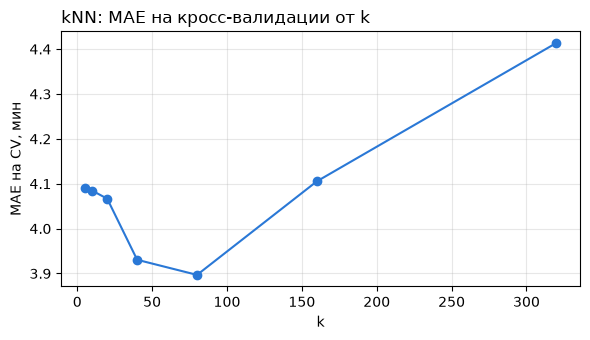

In [7]:
knn_train = train.sample(KNN_SAMPLE, random_state=SEED)
X_knn = make_features(knn_train, encoder, scaler)
y_knn = knn_train[TARGET].to_numpy()

knn_cv = pd.DataFrame({"k": KNN_K})
knn_cv["MAE_cv"] = [
    -cross_val_score(KNeighborsRegressor(n_neighbors=k), X_knn, y_knn, cv=cv, scoring="neg_mean_absolute_error").mean()
    for k in KNN_K
]
print(knn_cv.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(knn_cv["k"], knn_cv["MAE_cv"], marker="o", color="#2a78d6")
ax.set_xlabel("k")
ax.set_ylabel("MAE на CV, мин")
ax.set_title("kNN: MAE на кросс-валидации от k", loc="left")
ax.grid(alpha=0.3)
plt.tight_layout()

In [8]:
best_k = int(knn_cv.loc[knn_cv["MAE_cv"].idxmin(), "k"])
knn = KNeighborsRegressor(n_neighbors=best_k).fit(X_knn, y_knn)
# на train метрика по той же подвыборке, на которой kNN обучен
results.append({
    "model": f"kNN (k={best_k}, 20 тыс.)",
    "MSE_train": mean_squared_error(y_knn, knn.predict(X_knn)),
    "MSE_test": mean_squared_error(y_test, knn.predict(X_test)),
    "MAE_train": mean_absolute_error(y_knn, knn.predict(X_knn)),
    "MAE_test": mean_absolute_error(y_test, knn.predict(X_test)),
    "R2_train": r2_score(y_knn, knn.predict(X_knn)),
    "R2_test": r2_score(y_test, knn.predict(X_test)),
})

results_table = pd.DataFrame(results).set_index("model")
results_table.round(3)

,MSE_train,MSE_test,MAE_train,MAE_test,R2_train,R2_test
model,,,,,,
бейзлайн (среднее),73.331,93.795,6.569,7.248,0.000,-0.008
LinearRegression,30.063,42.694,3.859,4.374,0.590,0.541
"kNN (k=80, 20 тыс.)",29.768,47.254,3.828,4.557,0.586,0.492


**Вывод по моделям.**

1. Линейная регрессия лучше бейзлайна: MAE на test 4,37 < 7,25, R² 0,541 > −0,008.
2. Разрыв между train и test у линейной регрессии небольшой: MAE 3,86 и 4,37, R² 0,590 и 0,541.
3. MAE kNN на кросс-валидации снижается с 4,09 при k = 5 до минимума 3,90 при k = 80 и снова растёт до 4,41 при k = 320. При малом k прогноз зависит от немногих соседей и получается шумным, при большом усредняется по слишком непохожим поездкам.
4. kNN уступает линейной регрессии на test: MAE 4,56 > 4,37, R² 0,492 < 0,541. Он обучен на подвыборке 20 тыс. поездок вместо 101 тыс., и разрыв между train и test у него больше: MSE 29,8 и 47,3.

## 4. Связка с первым ноутбуком

Обучаем линейную регрессию на всём периоде `before` (октябрь — 19 декабря 2024) и применяем к `after` (с 6 января 2025). Модель знает только «старый» режим движения, поэтому остаток

$$r = \text{факт} - \text{прогноз}$$

показывает, насколько поездка стала дольше или короче, чем ожидалось при тех же расстоянии, часе, дне недели и районах. Сравниваем средний остаток для поездок внутри `cbd` и внутри `control` до и после платы. Остатки на `before` считаются на обучающих данных, их среднее около нуля по построению; интерес представляет сдвиг на `after`. Разность изменений между группами — ещё одна оценка эффекта на длительность, с поправкой на состав поездок.

In [9]:
before = trips[trips["period"] == "before"]
after = trips[trips["period"] == "after"]

encoder_before, scaler_before = fit_transformers(before)
model_before = LinearRegression().fit(make_features(before, encoder_before, scaler_before), before[TARGET])

linked = pd.concat([before, after]).copy()
linked["residual"] = linked[TARGET] - model_before.predict(make_features(linked, encoder_before, scaler_before))

# только поездки внутри одной группы, как в витрине mart.daily_group_metrics
same_group = (linked["pu_zone_group"] == linked["do_zone_group"]) & linked["pu_zone_group"].isin(["cbd", "control"])
linked = linked[same_group].rename(columns={"pu_zone_group": "zone_group"})

residuals = linked.groupby(["zone_group", "period"])["residual"].agg(["mean", "std", "count"])
residuals.round(3)

mean    std  count
zone_group period                     
cbd        after  -2.115  4.412  71275
           before -0.137  5.685  67092
control    after   0.092  3.941  11690
           before  0.155  3.794  10936

In [10]:
mean_res = residuals["mean"].unstack("period")[["before", "after"]]
mean_res["change"] = mean_res["after"] - mean_res["before"]
did_residual = mean_res.loc["cbd", "change"] - mean_res.loc["control", "change"]
print(f"разность изменений cbd − control: {did_residual:.3f} мин")
mean_res.round(3)

разность изменений cbd − control: -1.915 мин


period,before,after,change
zone_group,,,
cbd,-0.137,-2.115,-1.978
control,0.155,0.092,-0.063


**Вывод по связке.**

1. После введения платы средний остаток поездок внутри cbd сместился с −0,14 до −2,12 мин, в control с 0,16 до 0,09 мин. Разность изменений −1,92 мин: поездки внутри зоны стали короче, чем предсказывает модель, обученная до платы, а в контроле почти не изменились.
2. Знак согласуется с ростом скорости в зоне из первого ноутбука.
3. В отличие от сравнения средней скорости, здесь сопоставляются поездки с одинаковыми расстоянием, часом, днём недели и районами, поэтому изменение состава поездок по этим признакам учтено моделью.

## Выводы

1. Лучшая модель — линейная регрессия: средняя ошибка на тестовом периоде 4,37 мин (R² 0,541), бейзлайн ошибается на 7,25 мин. kNN с подобранным k = 80 уступает ей (4,56 мин).
2. Модель, обученная до введения платы, после него переоценивает длительность поездок внутри зоны: разность изменений средних остатков cbd и control составляет −1,92 мин. Это согласуется с эффектом на скорость в первом ноутбуке.
3. Ограничения:
   - признаки известны только в момент посадки, без информации о маршруте и дорожной ситуации;
   - модель линейная;
   - между периодом обучения и периодом применения прошло время, и кроме платы могли измениться другие факторы.